In [ ]:
import rasterio
import numpy as np
import pandas as pd
import geopandas as gpd

# Load the tree-cover raster
tree_cover_path = "satellite_data/tree_density_2024.tif"
tree_cover = rasterio.open(tree_cover_path)

# Inspect raster metadata
print("CRS:", tree_cover.crs) #coordinates reference system
print("Bounds:", tree_cover.bounds) #geographic extent covered by the raster
print("Resolution:", tree_cover.res) #ground dimensions represented by each pixel in m2.
print("Width:", tree_cover.width) #how many pixels the raster contains horizontally.
print("Height:", tree_cover.height) #how many pixels the raster contains vertically.
print("Bands:", tree_cover.count) #How many separate data layers are stored in the raster.
print("Data type:", tree_cover.dtypes) #how pixel values are stored.
print("NoData value:", tree_cover.nodata) #missing pixels
print("Metadata:", tree_cover.tags()) #more info

#showing same coordinates as imperviousness dataset, covering the Berlin area. Each pixel represents represents 100 m², the area is approximately 16.66 million pixels

CRS: PROJCS["ETRS89-extended / LAEA Europe",GEOGCS["ETRS89",DATUM["European_Terrestrial_Reference_System_1989",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6258"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4258"]],PROJECTION["Lambert_Azimuthal_Equal_Area"],PARAMETER["latitude_of_center",52],PARAMETER["longitude_of_center",10],PARAMETER["false_easting",4321000],PARAMETER["false_northing",3210000],UNIT["metre",1],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3035"]]
Bounds: BoundingBox(left=4531079.999999999, bottom=3254009.999987033, right=4576579.999983873, top=3290630.000000012)
Resolution: (9.999999996455808, 10.000000003544207)
Width: 4550
Height: 3662
Bands: 1
Data type: ('uint8',)
NoData value: None
Metadata: {'AREA_OR_POINT': 'Area'}


In [3]:
# Read the raster band
tree_cover_array = tree_cover.read(1)

# Inspect the pixel values
print("Shape:", tree_cover_array.shape)
print("Minimum:", tree_cover_array.min())
print("Maximum:", tree_cover_array.max())
print("Mean:", tree_cover_array.mean())
print("Median:", np.median(tree_cover_array))

# Inspect unique values and their frequencies
unique_values, counts = np.unique(
    tree_cover_array,
    return_counts=True
)

tree_cover_frequency = pd.DataFrame({
    "value": unique_values,
    "pixel_count": counts
})

print("\nNumber of unique values:", len(unique_values))
print("\nFirst 20 values:")
print(tree_cover_frequency.head(20))

print("\nLast 20 values:")
print(tree_cover_frequency.tail(20))

# Inspect additional raster metadata
print("\nBand metadata:", tree_cover.tags(1))

Shape: (3662, 4550)
Minimum: 0
Maximum: 100
Mean: 15.0565869248174
Median: 0.0

Number of unique values: 58

First 20 values:
    value  pixel_count
0       0     13751600
1      44            7
2      45           13
3      46            4
4      47            7
5      48            3
6      49            8
7      50           12
8      51          279
9      52          336
10     53          249
11     54          201
12     55         2090
13     56         3711
14     57         5259
15     58         8483
16     59        11705
17     60        20620
18     61        31498
19     62        36815

Last 20 values:
    value  pixel_count
38     81        30113
39     82        34315
40     83        31798
41     84        37385
42     85        36171
43     86        43012
44     87        44456
45     88        54041
46     89        58078
47     90        70086
48     91        84706
49     92       104229
50     93       129603
51     94       183040
52     95       259880
53    

In [5]:
# Load the Berlin neighbourhood boundaries
lor_boundaries = gpd.read_file("satellite_data/berlin_lor_2021.geojson")

# Reproject them to the raster CRS
lor_tree_crs = lor_boundaries.to_crs(tree_cover.crs)

# Compare raster and neighbourhood bounds
print("Raster bounds:", tree_cover.bounds)
print("LOR bounds:", lor_tree_crs.total_bounds)

# Check spatial overlap
print(
    "Raster covers LOR bounding box:",
    (
        tree_cover.bounds.left <= lor_tree_crs.total_bounds[0]
        and tree_cover.bounds.bottom <= lor_tree_crs.total_bounds[1]
        and tree_cover.bounds.right >= lor_tree_crs.total_bounds[2]
        and tree_cover.bounds.top >= lor_tree_crs.total_bounds[3]
    )
)

print("Number of neighbourhoods:", len(lor_tree_crs))
print("Unique neighbourhood IDs:", lor_tree_crs["bzr_id"].nunique())

Raster bounds: BoundingBox(left=4531079.999999999, bottom=3254009.999987033, right=4576579.999983873, top=3290630.000000012)
LOR bounds: [4531042.78524706 3253863.7207419  4576654.31977647 3290794.75294586]
Raster covers LOR bounding box: False
Number of neighbourhoods: 143
Unique neighbourhood IDs: 143


In [6]:
from shapely.geometry import box

# Create a polygon representing the raster's spatial extent
raster_footprint = box(
    tree_cover.bounds.left,
    tree_cover.bounds.bottom,
    tree_cover.bounds.right,
    tree_cover.bounds.top
)

# Calculate the area of each neighbourhood outside the raster
lor_coverage = lor_tree_crs[["bzr_id", "bzr_name", "geometry"]].copy()

lor_coverage["lor_area_m2"] = lor_coverage.geometry.area

lor_coverage["outside_raster_m2"] = (
    lor_coverage.geometry
    .difference(raster_footprint)
    .area
)

lor_coverage["outside_raster_pct"] = (
    lor_coverage["outside_raster_m2"]
    / lor_coverage["lor_area_m2"] * 100
)

# Inspect coverage across all neighbourhoods
print("Neighbourhoods:", len(lor_coverage))
print(
    "Neighbourhoods fully covered:",
    (lor_coverage["outside_raster_m2"] < 1).sum()
)
print(
    "Neighbourhoods with some area outside:",
    (lor_coverage["outside_raster_m2"] >= 1).sum()
)

print("\nOutside raster area (%):")
print(lor_coverage["outside_raster_pct"].describe())

# Show neighbourhoods with the greatest uncovered area
print("\n10 neighbourhoods with the most area outside the raster:")
print(
    lor_coverage.nlargest(10, "outside_raster_pct")[
        ["bzr_id", "bzr_name", "outside_raster_m2", "outside_raster_pct"]
    ]
)

Neighbourhoods: 143
Neighbourhoods fully covered: 139
Neighbourhoods with some area outside: 4

Outside raster area (%):
count    143.000000
mean       0.002881
std        0.024271
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        0.273655
Name: outside_raster_pct, dtype: float64

10 neighbourhoods with the most area outside the raster:
     bzr_id            bzr_name  outside_raster_m2  outside_raster_pct
100  093012         Schmöckwitz       46849.154156            0.273655
18   031001                Buch       21022.011413            0.091458
106  095018           Rahnsdorf        8374.195299            0.039040
60   064007  Zehlendorf Südwest        3379.979204            0.007796
0    011001      Tiergarten Süd           0.000000            0.000000
1    011002   Regierungsviertel           0.000000            0.000000
2    011003      Alexanderplatz           0.000000            0.000000
3    011004   Brunnenstraße Süd           0.000000  

Following areas are outside of the tree density dataset:

Schmöckwitz: 0.2737% outside

Buch: 0.0915% outside

Rahnsdorf: 0.0390% outside

Zehlendorf Südwest: 0.0078% outside

In [ ]:
from rasterio.mask import mask
from shapely.geometry import mapping

# Prepare a list to store neighbourhood-level results
tree_cover_results = []

# Extract raster values for each neighbourhood
for index, row in lor_tree_crs.iterrows():
    geometry = row.geometry

    out_image, out_transform = mask(
        tree_cover,
        [mapping(geometry)],
        crop=True,
        filled=False,
        all_touched=False
    )

    # Exclude pixels outside the neighbourhood geometry
    pixels = out_image[0].compressed()

    tree_cover_results.append({
        "bzr_id": row["bzr_id"],
        "bzr_name": row["bzr_name"],
        "bez": row["bez"],
        "tree_cover_mean": pixels.mean(),
        "tree_cover_median": np.median(pixels),
        "tree_cover_pixels_pct": (pixels > 0).mean() * 100,
        "pixel_count": len(pixels)
    })

# Create the neighbourhood-level dataset
tree_cover_by_lor = pd.DataFrame(tree_cover_results)

# Inspect the results
print("Shape:", tree_cover_by_lor.shape)
print("Unique neighbourhoods:", tree_cover_by_lor["bzr_id"].nunique())
print("Missing values:", tree_cover_by_lor.isna().sum().sum())

print("\nSummary statistics:")
print(tree_cover_by_lor.describe())



"""
The mean of tree_cover_mean across neighbourhoods is 17.26.
The median neighbourhood has a tree_cover_mean of 12.08.
At least 75% of neighbourhoods have a tree_cover_median of zero. This suggests many neighbourhoods have zero-valued pixels across at least half their area.
The share of non-zero pixels varies substantially, from 1.09% to 74.15%.
"""


Shape: (143, 7)
Unique neighbourhoods: 143
Missing values: 0

Summary statistics:
       tree_cover_mean  tree_cover_median  tree_cover_pixels_pct  \
count       143.000000         143.000000             143.000000   
mean         17.264584           8.160839              21.117535   
std          15.354378          25.030024              16.563850   
min           0.754692           0.000000               1.086876   
25%           7.127378           0.000000              10.177425   
50%          12.083633           0.000000              16.107893   
75%          20.343926           0.000000              25.337022   
max          66.214962          94.000000              74.154476   

         pixel_count  
count     143.000000  
mean    62310.790210  
std     63695.554876  
min      7124.000000  
25%     23452.000000  
50%     40918.000000  
75%     70677.500000  
max    433534.000000  


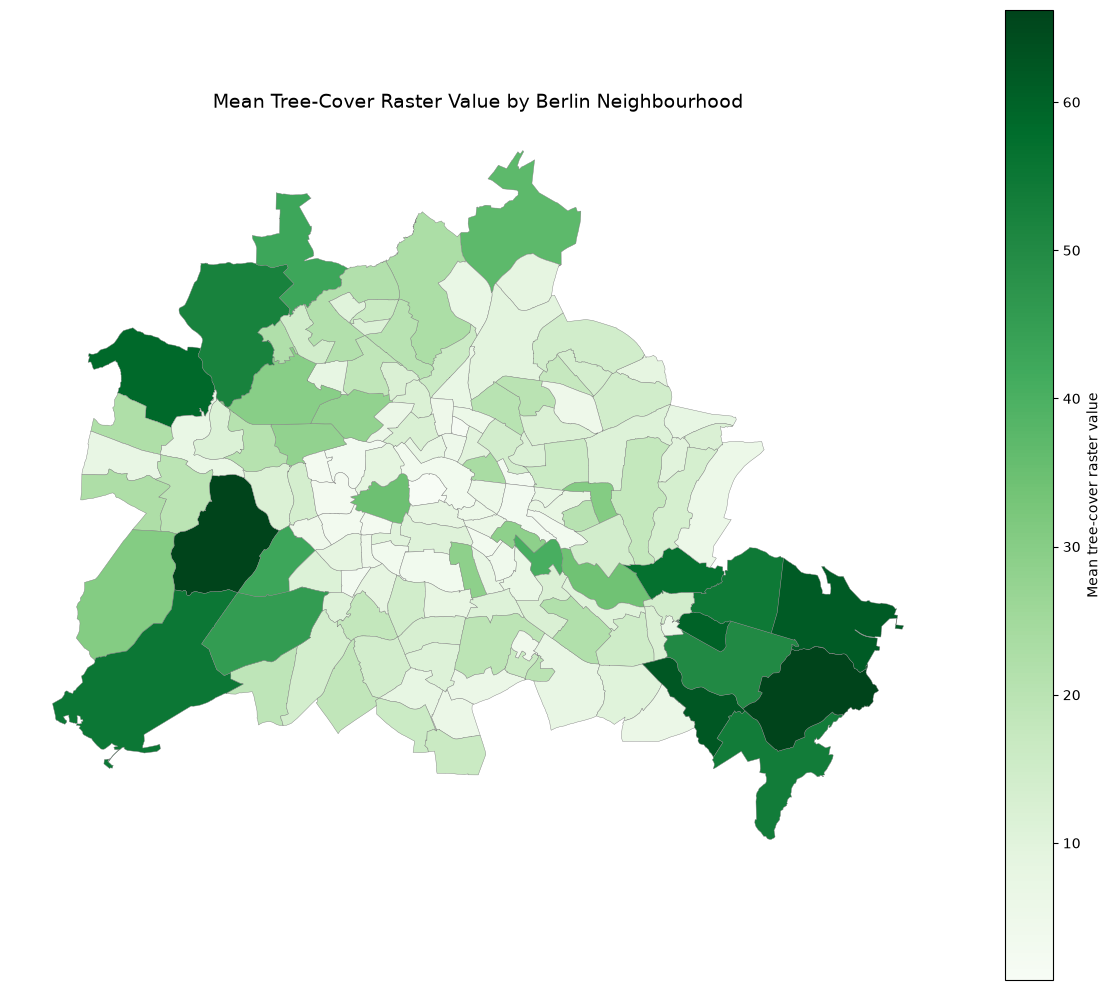

In [8]:
import matplotlib.pyplot as plt

# Create the map
fig, ax = plt.subplots(figsize=(12, 10))

lor_tree_cover = lor_tree_crs.merge(
    tree_cover_by_lor,
    on=["bzr_id", "bzr_name", "bez"],
    how="left",
    validate="one_to_one"
)

# Plot mean tree-cover raster values
lor_tree_cover.plot(
    column="tree_cover_mean",
    cmap="Greens",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    legend_kwds={"label": "Mean tree-cover raster value"},
    ax=ax
)

# Add title and remove axes
ax.set_title(
    "Mean Tree-Cover Raster Value by Berlin Neighbourhood",
    fontsize=14
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [13]:
# Inspect neighbourhood ID data types
print("Tree cover:", tree_cover_by_lor["bzr_id"].dtype)
print("Imperviousness:", imperviousness_by_lor["bzr_id"].dtype)
print("Land cover:", land_cover_final["bzr_id"].dtype)

Tree cover: str
Imperviousness: str
Land cover: str


In [12]:
# Standardise neighbourhood IDs
tree_cover_by_lor["bzr_id"] = tree_cover_by_lor["bzr_id"].astype(str)
imperviousness_by_lor["bzr_id"] = imperviousness_by_lor["bzr_id"].astype(str)
land_cover_final["bzr_id"] = land_cover_final["bzr_id"].astype(str)

In [16]:
# Check the data type of each neighbourhood ID column
datasets = {
    "tree_cover_by_lor": tree_cover_by_lor,
    "imperviousness_by_lor": imperviousness_by_lor,
    "land_cover_final": land_cover_final
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Column dtype:", df["bzr_id"].dtype)
    print("Python type of first ID:", type(df["bzr_id"].iloc[0]))
    print("First 5 IDs:", df["bzr_id"].head().tolist())


tree_cover_by_lor
Column dtype: str
Python type of first ID: <class 'str'>
First 5 IDs: ['011001', '011002', '011003', '011004', '012005']

imperviousness_by_lor
Column dtype: int64
Python type of first ID: <class 'numpy.int64'>
First 5 IDs: [11001, 11002, 11003, 11004, 12005]

land_cover_final
Column dtype: int64
Python type of first ID: <class 'numpy.int64'>
First 5 IDs: [11001, 11002, 11003, 11004, 12005]


In [17]:
# Convert all neighbourhood IDs to six-character strings
for df in [
    tree_cover_by_lor,
    imperviousness_by_lor,
    land_cover_final
]:
    df["bzr_id"] = df["bzr_id"].astype(str).str.zfill(6)

# Verify the conversion
print("Tree cover:", tree_cover_by_lor["bzr_id"].head().tolist())
print("Imperviousness:", imperviousness_by_lor["bzr_id"].head().tolist())
print("Land cover:", land_cover_final["bzr_id"].head().tolist())

Tree cover: ['011001', '011002', '011003', '011004', '012005']
Imperviousness: ['011001', '011002', '011003', '011004', '012005']
Land cover: ['011001', '011002', '011003', '011004', '012005']


In [18]:
# Merge the three datasets
tree_cover_comparison = (
    tree_cover_by_lor
    .merge(
        imperviousness_by_lor[
            ["bzr_id", "imperviousness_mean"]
        ],
        on="bzr_id",
        validate="one_to_one"
    )
    .merge(
        land_cover_final[
            ["bzr_id", "green_natural"]
        ],
        on="bzr_id",
        validate="one_to_one"
    )
)

# Calculate correlations
correlations = tree_cover_comparison[
    [
        "tree_cover_mean",
        "green_natural",
        "imperviousness_mean"
    ]
].corr()

print(correlations)

                     tree_cover_mean  green_natural  imperviousness_mean
tree_cover_mean             1.000000       0.922579            -0.795554
green_natural               0.922579       1.000000            -0.758838
imperviousness_mean        -0.795554      -0.758838             1.000000


In [20]:
# Load the previously processed datasets
imperviousness_by_lor = pd.read_csv(
    "merged_complete_datasets/imperviousness_by_lor.csv",
    dtype={"bzr_id": str}
)

land_cover_final = pd.read_csv(
    "merged_complete_datasets/berlin_land_cover_by_neighbourhood.csv",
    dtype={"bzr_id": str}
)

# Standardise IDs to six characters, preserving leading zeros
imperviousness_by_lor["bzr_id"] = (
    imperviousness_by_lor["bzr_id"].str.zfill(6)
)

land_cover_final["bzr_id"] = (
    land_cover_final["bzr_id"].str.zfill(6)
)

tree_cover_by_lor["bzr_id"] = (
    tree_cover_by_lor["bzr_id"].astype(str).str.zfill(6)
)

# Check the data types
print("Tree cover:", tree_cover_by_lor["bzr_id"].dtype)
print("Imperviousness:", imperviousness_by_lor["bzr_id"].dtype)
print("Land cover:", land_cover_final["bzr_id"].dtype)

Tree cover: str
Imperviousness: str
Land cover: str


In [22]:
# Check the data types and sample IDs in all three DataFrames
datasets = {
    "tree_cover_by_lor": tree_cover_by_lor,
    "imperviousness_by_lor": imperviousness_by_lor,
    "land_cover_final": land_cover_final
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Data type:", df["bzr_id"].dtype)
    print("Python type:", type(df["bzr_id"].iloc[0]))
    print("Sample IDs:", df["bzr_id"].head().tolist())


tree_cover_by_lor
Data type: str
Python type: <class 'str'>
Sample IDs: ['011001', '011002', '011003', '011004', '012005']

imperviousness_by_lor
Data type: int64
Python type: <class 'numpy.int64'>
Sample IDs: [11001, 11002, 11003, 11004, 12005]

land_cover_final
Data type: int64
Python type: <class 'numpy.int64'>
Sample IDs: [11001, 11002, 11003, 11004, 12005]


In [23]:
# Standardise all neighbourhood IDs
for df in datasets.values():
    df["bzr_id"] = df["bzr_id"].astype(str).str.zfill(6)

# Check data types again
print("\nData types before merging:")
for name, df in datasets.items():
    print(name, df["bzr_id"].dtype)

# First merge: tree cover + imperviousness
tree_cover_comparison = tree_cover_by_lor.merge(
    imperviousness_by_lor[["bzr_id", "imperviousness_mean"]],
    on="bzr_id",
    validate="one_to_one"
)

print("\nFirst merge successful:", tree_cover_comparison.shape)

# Second merge: add green/natural land cover
tree_cover_comparison = tree_cover_comparison.merge(
    land_cover_final[["bzr_id", "green_natural"]],
    on="bzr_id",
    validate="one_to_one"
)

print("Second merge successful:", tree_cover_comparison.shape)

# Calculate Pearson correlations
correlations = tree_cover_comparison[
    ["tree_cover_mean", "green_natural", "imperviousness_mean"]
].corr()

print(correlations)


Data types before merging:
tree_cover_by_lor str
imperviousness_by_lor str
land_cover_final str

First merge successful: (143, 8)
Second merge successful: (143, 9)
                     tree_cover_mean  green_natural  imperviousness_mean
tree_cover_mean             1.000000       0.922579            -0.795554
green_natural               0.922579       1.000000            -0.758838
imperviousness_mean        -0.795554      -0.758838             1.000000


In [24]:
# Save the combined neighbourhood indicators
tree_cover_comparison.to_csv(
    "tree_cover_comparison.csv",
    index=False
)

In [45]:
tree_cover_by_lor.head()

,bzr_id,bzr_name,bez,tree_cover_mean,tree_cover_median,tree_cover_pixels_pct,pixel_count
0,011001,Tiergarten Süd,01 - Mitte,34.611350,0.0,39.338747,51720
1,011002,Regierungsviertel,01 - Mitte,0.754692,0.0,1.086876,26958
2,011003,Alexanderplatz,01 - Mitte,3.760034,0.0,5.551631,62288
3,011004,Brunnenstraße Süd,01 - Mitte,7.928254,0.0,11.100980,17548
4,012005,Moabit West,01 - Mitte,2.914996,0.0,4.193286,43045


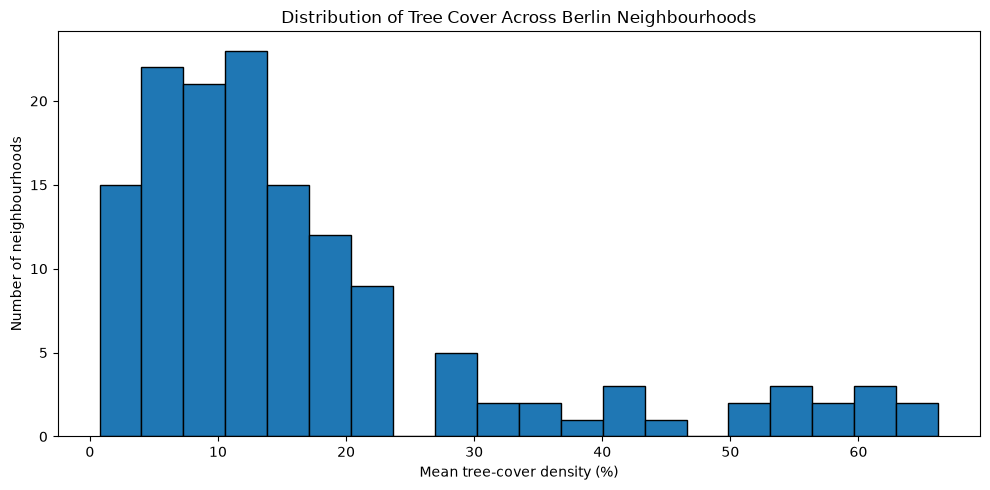

In [26]:
# Plot the distribution of mean tree-cover density
plt.figure(figsize=(10, 5))

plt.hist(
    tree_cover_by_lor["tree_cover_mean"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Mean tree-cover density (%)")
plt.ylabel("Number of neighbourhoods")
plt.title("Distribution of Tree Cover Across Berlin Neighbourhoods")

plt.tight_layout()
plt.show()

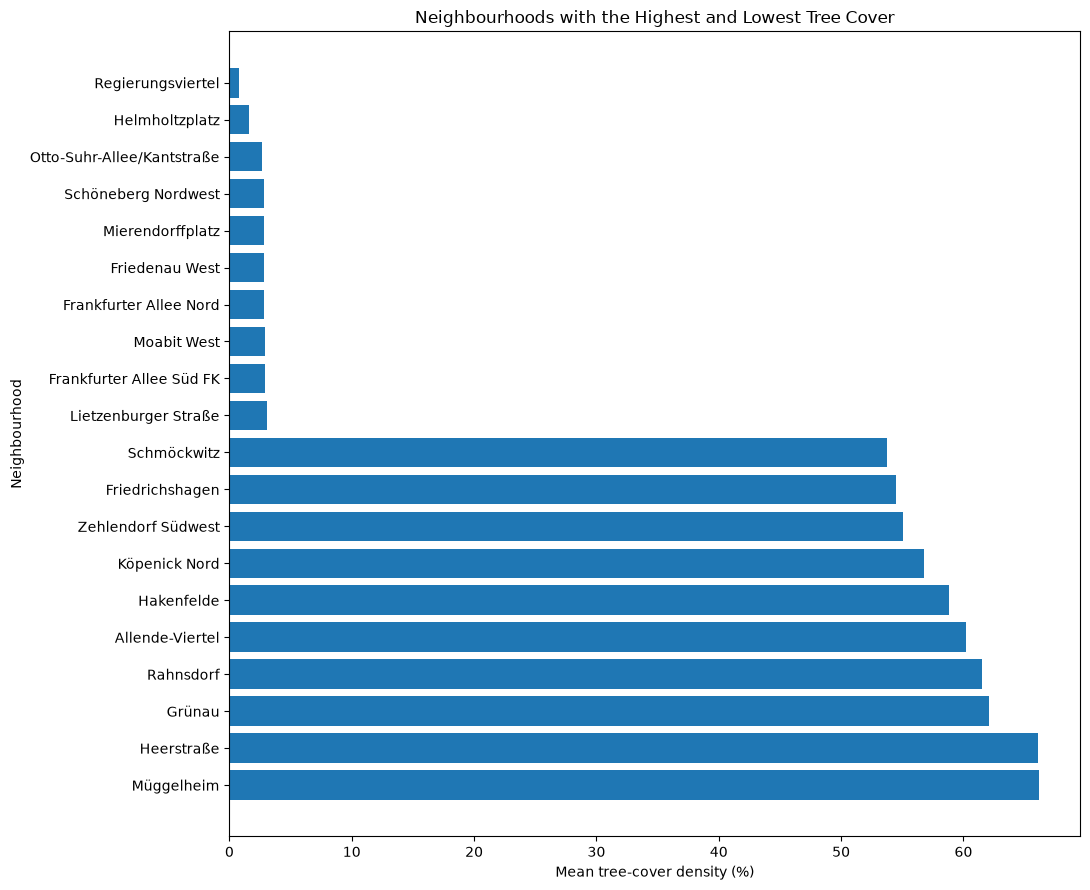

In [27]:
# Select the 10 neighbourhoods with the highest and lowest tree cover
tree_cover_ranked = tree_cover_by_lor.sort_values(
    "tree_cover_mean",
    ascending=False
)

top_10 = tree_cover_ranked.head(10)
bottom_10 = tree_cover_ranked.tail(10)

# Combine both groups
tree_cover_extremes = pd.concat([top_10, bottom_10])

# Plot the results
plt.figure(figsize=(11, 9))

plt.barh(
    tree_cover_extremes["bzr_name"],
    tree_cover_extremes["tree_cover_mean"]
)

plt.xlabel("Mean tree-cover density (%)")
plt.ylabel("Neighbourhood")
plt.title("Neighbourhoods with the Highest and Lowest Tree Cover")

plt.tight_layout()
plt.show()

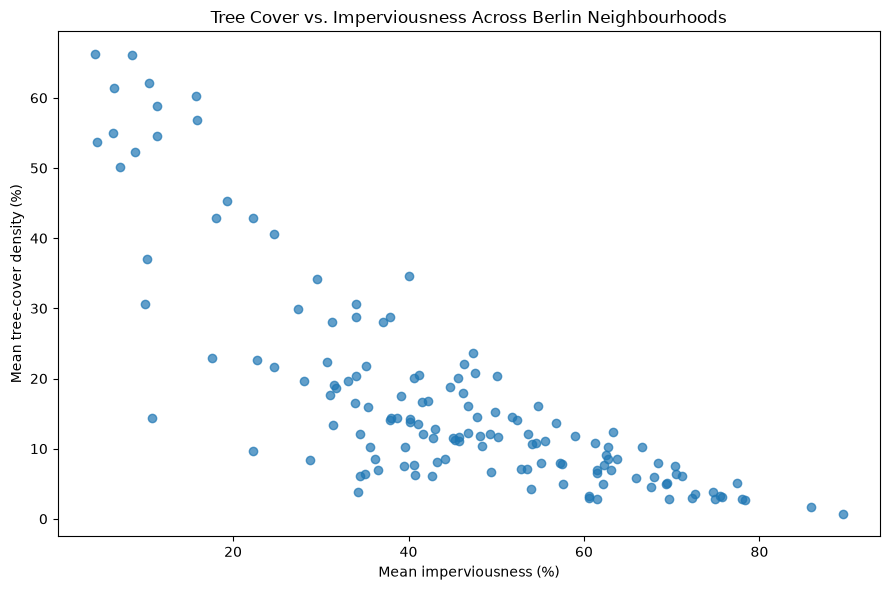

In [28]:
# Plot the relationship between imperviousness and tree cover
plt.figure(figsize=(9, 6))

plt.scatter(
    tree_cover_comparison["imperviousness_mean"],
    tree_cover_comparison["tree_cover_mean"],
    alpha=0.7
)

plt.xlabel("Mean imperviousness (%)")
plt.ylabel("Mean tree-cover density (%)")
plt.title("Tree Cover vs. Imperviousness Across Berlin Neighbourhoods")

plt.tight_layout()
plt.show()

In [30]:
# Combine the three indicators with the LOR geometries
lor_three_densities = lor_tree_crs.merge(
    tree_cover_comparison,
    on=["bzr_id", "bzr_name", "bez"],
    how="left",
    validate="one_to_one"
)

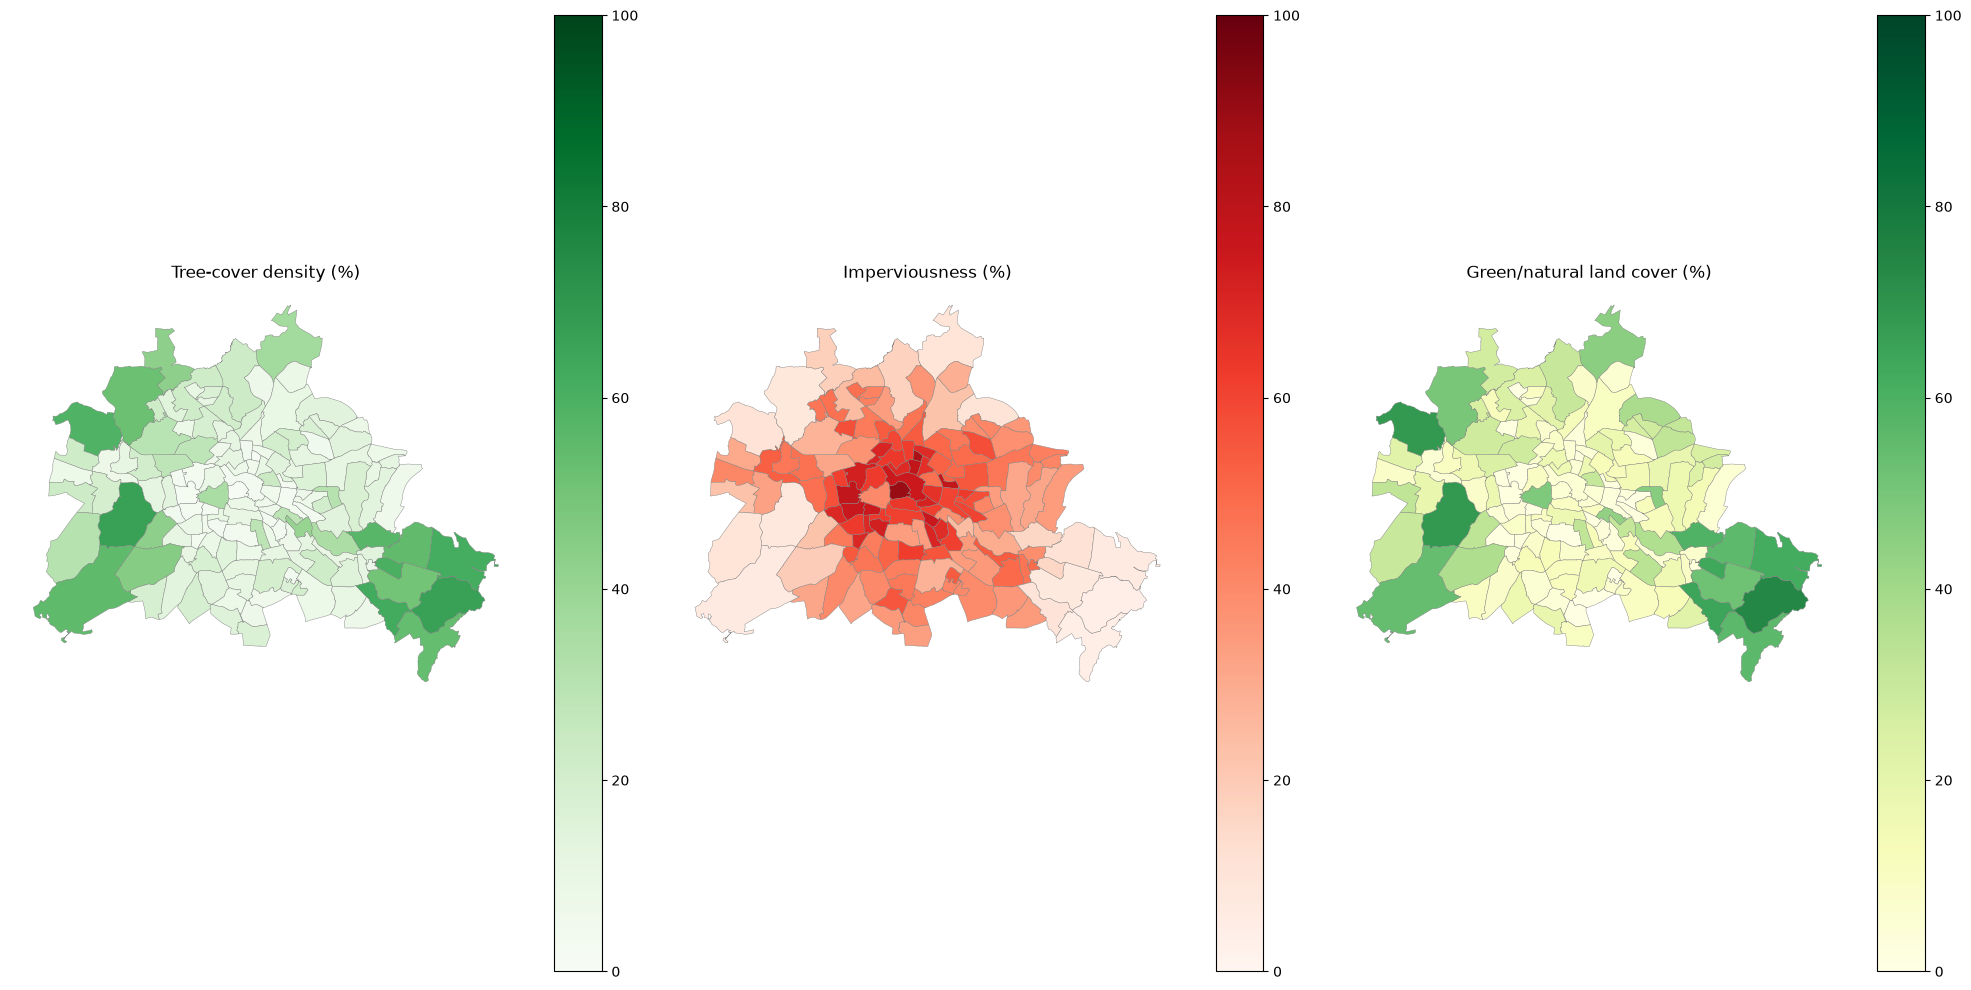

In [34]:
# Create three maps side by side
fig, axes = plt.subplots(1, 3, figsize=(20, 10))

# Tree-cover density
lor_three_densities.plot(
    column="tree_cover_mean",
    cmap="Greens",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    ax=axes[0],
    vmin=0,
    vmax=100,
)
axes[0].set_title("Tree-cover density (%)")

# Imperviousness
lor_three_densities.plot(
    column="imperviousness_mean",
    cmap="Reds",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    ax=axes[1],
    vmin=0,
    vmax=100,
)
axes[1].set_title("Imperviousness (%)")

# Green and natural land cover
lor_three_densities.plot(
    column="green_natural",
    cmap="YlGn",
    linewidth=0.3,
    edgecolor="grey",
    legend=True,
    ax=axes[2],
    vmin=0,
    vmax=100,
)
axes[2].set_title("Green/natural land cover (%)")

# Remove map axes
for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [38]:
# Check the LOR geometry object
print(type(lor_tree_crs))
print(lor_tree_crs.columns)
print(lor_tree_crs.crs)

<class 'geopandas.geodataframe.GeoDataFrame'>
Index(['id', 'bzr_id', 'bzr_name', 'pgr_id', 'pgr_name', 'bez', 'finhalt',
       'stand', 'geometry'],
      dtype='str')
PROJCS["ETRS89-extended / LAEA Europe",GEOGCS["ETRS89",DATUM["European_Terrestrial_Reference_System_1989",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6258"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4258"]],PROJECTION["Lambert_Azimuthal_Equal_Area"],PARAMETER["latitude_of_center",52],PARAMETER["longitude_of_center",10],PARAMETER["false_easting",4321000],PARAMETER["false_northing",3210000],UNIT["metre",1],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3035"]]


In [39]:
# Attach the three density indicators to the LOR geometries
lor_three_densities = lor_tree_crs.merge(
    tree_cover_comparison,
    on=["bzr_id", "bzr_name", "bez"],
    how="left",
    validate="one_to_one"
)

In [ ]:
#final check on shape, missing values etc.
print(type(lor_three_densities))
print("Shape:", lor_three_densities.shape)
print("CRS:", lor_three_densities.crs)
print("Missing values:")
print(lor_three_densities[
    ["tree_cover_mean", "imperviousness_mean", "green_natural"]
].isna().sum())

<class 'geopandas.geodataframe.GeoDataFrame'>
Shape: (143, 15)
CRS: PROJCS["ETRS89-extended / LAEA Europe",GEOGCS["ETRS89",DATUM["European_Terrestrial_Reference_System_1989",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6258"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4258"]],PROJECTION["Lambert_Azimuthal_Equal_Area"],PARAMETER["latitude_of_center",52],PARAMETER["longitude_of_center",10],PARAMETER["false_easting",4321000],PARAMETER["false_northing",3210000],UNIT["metre",1],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","3035"]]
Missing values:
tree_cover_mean        0
imperviousness_mean    0
green_natural          0
dtype: int64


In [42]:
# Check the ranges and descriptive statistics
density_columns = [
    "tree_cover_mean",
    "imperviousness_mean",
    "green_natural"
]

print(lor_three_densities[density_columns].describe())

       tree_cover_mean  imperviousness_mean  green_natural
count       143.000000           143.000000     143.000000
mean         17.264584            44.636112      17.725954
std          15.354378            19.168424      17.066497
min           0.754692             4.263654       0.000000
25%           7.127378            34.006995       5.175106
50%          12.083633            44.734282      11.782912
75%          20.343926            59.777921      25.176581
max          66.214962            89.484086      73.929954


In [43]:
# Check whether any indicator contains values outside 0–100
for column in density_columns:
    print(
        column,
        "Below 0:", (lor_three_densities[column] < 0).sum(),
        "Above 100:", (lor_three_densities[column] > 100).sum()
    )

tree_cover_mean Below 0: 0 Above 100: 0
imperviousness_mean Below 0: 0 Above 100: 0
green_natural Below 0: 0 Above 100: 0
